In [3]:
import pandas as pd
import numpy as np
import datetime as dt

In [4]:
# 1. Load Data
df = pd.read_excel('/content/Online_Retail.xlsx')

In [5]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [11]:
# 2. Basic Cleaning
# Drop rows without CustomerID
df = df.dropna(subset=['CustomerID'])
df['CustomerID'] = df['CustomerID'].astype(int)

# Exclude cancellations (Invoices starting with 'C' or negative quantities)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Compute total transaction spend
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

In [12]:
# 3. Define Reference Date (1 day after the latest transaction in data)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

In [13]:
# 4. Aggregate RFM Metrics per Customer
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                  # Frequency
    'TotalAmount': 'sum'                                     # Monetary
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Round monetary for clean display
rfm['Monetary'] = rfm['Monetary'].round(2)

print("RFM Table Preview:")
print(rfm.head())

RFM Table Preview:
   CustomerID  Recency  Frequency  Monetary
0       12346      326          1  77183.60
1       12347        2          7   4310.00
2       12348       75          4   1797.24
3       12349       19          1   1757.55
4       12350      310          1    334.40


In [14]:
# 5. Calculate R, F, and M scores (1-5 scale)

# Recency: labels 5 to 1 (reversed)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])

# Frequency: rank method handles tied counts smoothly
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

# Monetary: labels 1 to 5
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

# Combine into a single string score (e.g., '555', '111')
rfm['RFM_Group'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# Calculate composite numeric RFM score
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Group  \
0       12346      326          1  77183.60       1       1       5       115   
1       12347        2          7   4310.00       5       5       5       555   
2       12348       75          4   1797.24       2       4       4       244   
3       12349       19          1   1757.55       4       1       4       414   
4       12350      310          1    334.40       1       1       2       112   

   RFM_Score  
0          7  
1         15  
2         10  
3          9  
4          4  


In [15]:
# 6. Segment mapping using regex on R and F scores
seg_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At Risk',
    r'[1-2]5': 'Cannot Lose Them',
    r'3[1-2]': 'About To Sleep',
    r'33': 'Need Attention',
    r'[3-4][4-5]': 'Loyal Customers',
    r'41': 'Promising',
    r'51': 'New Customers',
    r'[4-5][2-3]': 'Potential Loyalists',
    r'5[4-5]': 'Champions'
}

rfm['Segment'] = (rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str)).replace(seg_map, regex=True)

# 7. Summary table by segment
segment_summary = rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

segment_summary.columns = ['Avg_Recency', 'Avg_Frequency', 'Avg_Monetary', 'Customer_Count']
segment_summary['%_of_Customers'] = ((segment_summary['Customer_Count'] / len(rfm)) * 100).round(2)

print("\n--- Segment Summary ---")
print(segment_summary.sort_values(by='Customer_Count', ascending=False))


--- Segment Summary ---
                     Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Count  \
Segment                                                                         
Hibernating               217.90           1.10        487.71            1065   
Loyal Customers            33.47           6.46       2856.72             827   
Champions                   5.88          12.41       6857.94             633   
At Risk                   155.06           2.86       1076.51             580   
Potential Loyalists        17.12           2.01       1034.91             492   
About To Sleep             53.50           1.16        461.06             351   
Need Attention             53.06           2.33        889.23             186   
Promising                  23.44           1.00        355.35              99   
Cannot Lose Them          132.43           8.38       2796.16              63   
New Customers               6.86           1.00        388.21              42   

  

/tmp/ipykernel_757/412438112.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_757/412438112.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_757/412438112.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_757/412438112.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_757/412438112.py:13: FutureWarnin

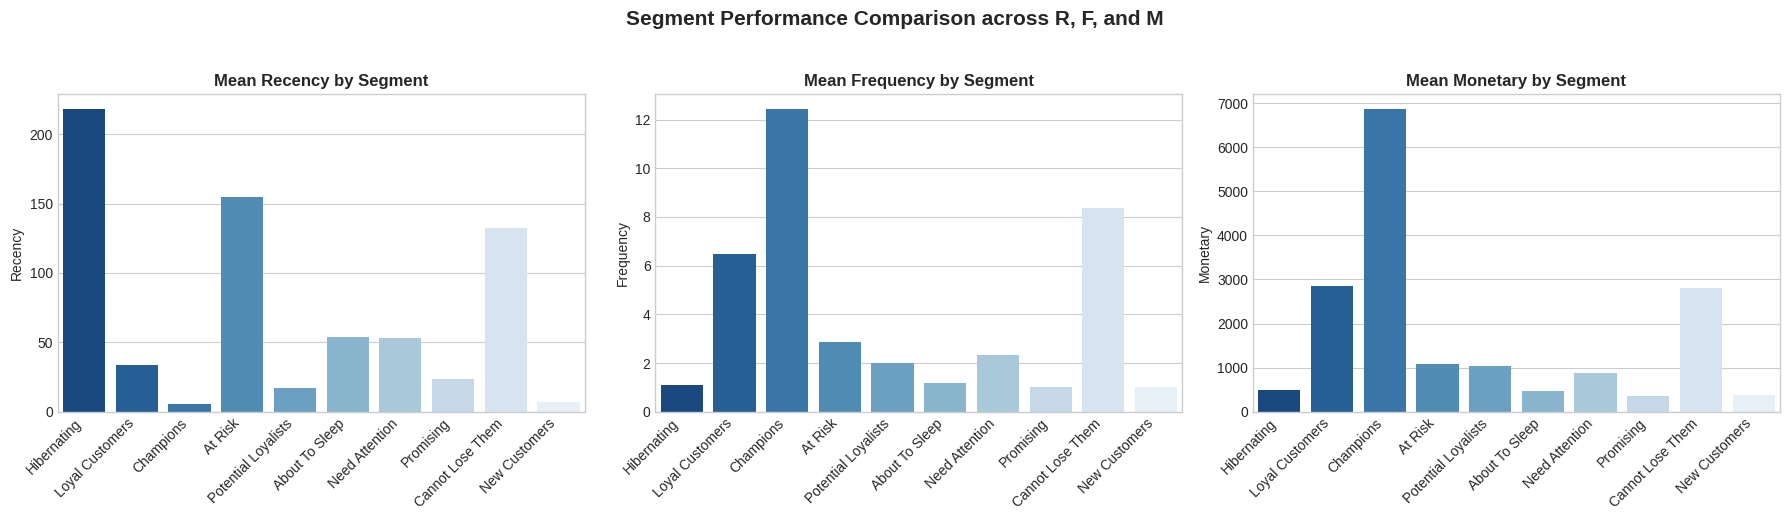

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

#Bar Chart: Average RFM Metrics per Segment

metrics = ['Recency', 'Frequency', 'Monetary']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Order segments logically by customer count
order = rfm['Segment'].value_counts().index

for i, metric in enumerate(metrics):
    sns.barplot(
        data=rfm,
        x='Segment',
        y=metric,
        order=order,
        estimator='mean',
        errorbar=None,
        palette='Blues_r',
        ax=axes[i]
    )
    axes[i].set_title(f'Mean {metric} by Segment', fontsize=12, weight='bold')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
    axes[i].set_xlabel('')
    axes[i].set_ylabel(metric)

plt.suptitle('Segment Performance Comparison across R, F, and M', fontsize=15, weight='bold', y=1.03)
plt.tight_layout()
plt.show()